# Image Classification with a CNN — CIFAR-10 (Colab-ready)

**Before running:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.

Fixes vs. the original notebook:
- Gradio installed in the first cell (no mid-notebook installs)
- Fixed random seed for reproducible results
- Stratified validation split
- Rotation set to ±15° (the old `0.10` meant ±36°)
- Fast `tf.data` input pipeline, more epochs (EarlyStopping decides when to stop)
- EarlyStopping and ModelCheckpoint both watch `val_loss`, so the saved model is the best model
- `CLASS_NAMES` is never overwritten; emoji labels live in a separate `DISPLAY_NAMES` list
- `predict_single` displays the image correctly
- Gradio app handles empty submissions, any image mode, and non-square photos (centre crop)
- `flagging_mode` replaces the deprecated `allow_flagging`

In [1]:
# ── 0. Install Gradio (runs first so no runtime restart is needed later)
!pip install -q gradio

In [2]:
# ── 1. Imports & setup ───────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow :", tf.__version__)
print("GPU        :", gpus if gpus else "NONE - enable it via Runtime > Change runtime type")

TensorFlow : 2.21.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1347s 8us/step
X_full : (50000, 32, 32, 3)   y_full : (50000,)
X_test : (10000, 32, 32, 3)   y_test : (10000,)
Pixel range: 0 - 255


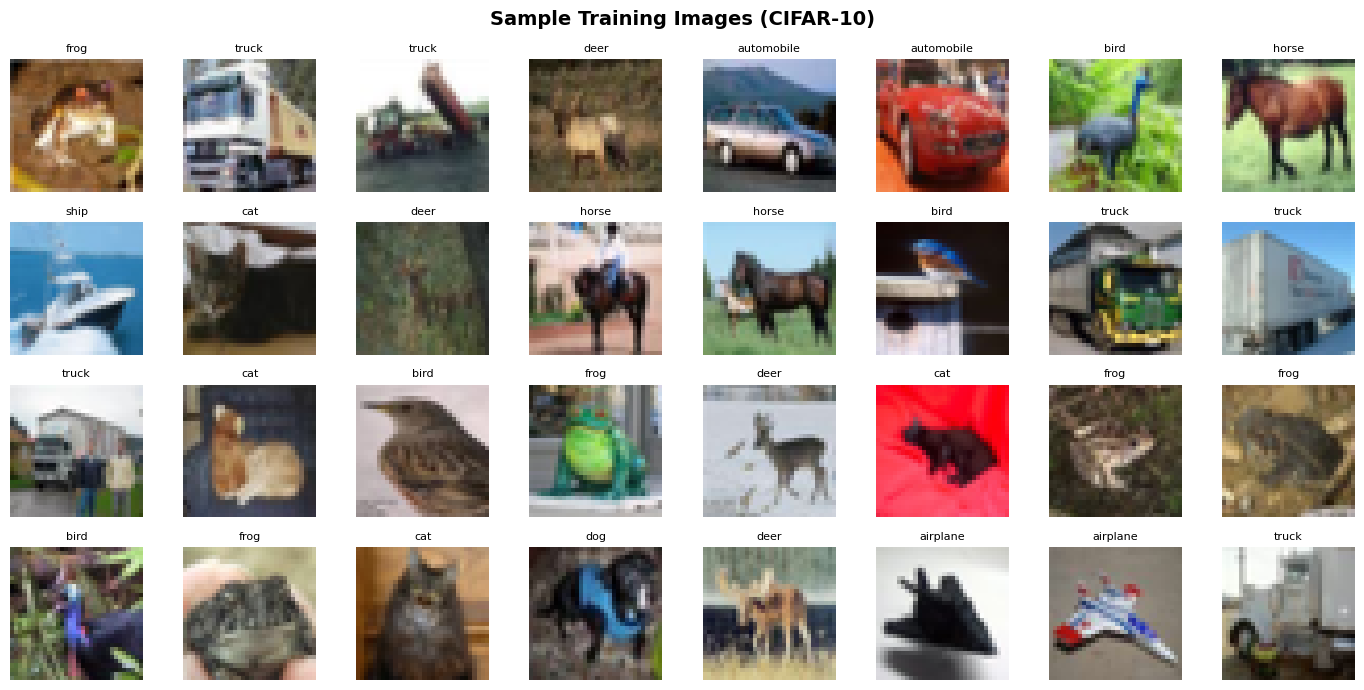

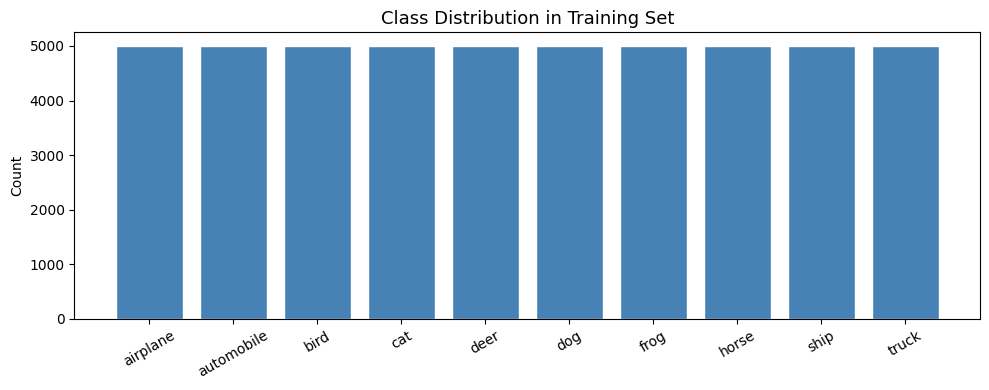

In [3]:
# ── 2. Load & explore CIFAR-10 ──────────────────────────────────────
(X_full, y_full), (X_test, y_test) = keras.datasets.cifar10.load_data()
y_full, y_test = y_full.flatten(), y_test.flatten()

CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
NUM_CLASSES = len(CLASS_NAMES)

print(f"X_full : {X_full.shape}   y_full : {y_full.shape}")
print(f"X_test : {X_test.shape}   y_test : {y_test.shape}")
print(f"Pixel range: {X_full.min()} - {X_full.max()}")

fig, axes = plt.subplots(4, 8, figsize=(14, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_full[i])
    ax.set_title(CLASS_NAMES[y_full[i]], fontsize=8)
    ax.axis("off")
plt.suptitle("Sample Training Images (CIFAR-10)", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

counts = np.bincount(y_full, minlength=NUM_CLASSES)
plt.figure(figsize=(10, 4))
plt.bar(CLASS_NAMES, counts, color="steelblue", edgecolor="white")
plt.title("Class Distribution in Training Set", fontsize=13)
plt.ylabel("Count"); plt.xticks(rotation=30)
plt.tight_layout(); plt.show()

In [4]:
# ── 3. Normalise, split, one-hot encode ─────────────────────────────
X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=0.1, random_state=SEED, stratify=y_full
)

X_train = X_train.astype("float32") / 255.0
X_val   = X_val.astype("float32")   / 255.0
X_test  = X_test.astype("float32")  / 255.0

y_train_ohe = keras.utils.to_categorical(y_train, NUM_CLASSES)
y_val_ohe   = keras.utils.to_categorical(y_val,   NUM_CLASSES)
y_test_ohe  = keras.utils.to_categorical(y_test,  NUM_CLASSES)

print(f"Train : {len(X_train)}   Val : {len(X_val)}   Test : {len(X_test)}")
print(f"Pixel range after normalisation: {X_train.min():.1f} - {X_train.max():.1f}")

Train : 45000   Val : 5000   Test : 10000
Pixel range after normalisation: 0.0 - 1.0


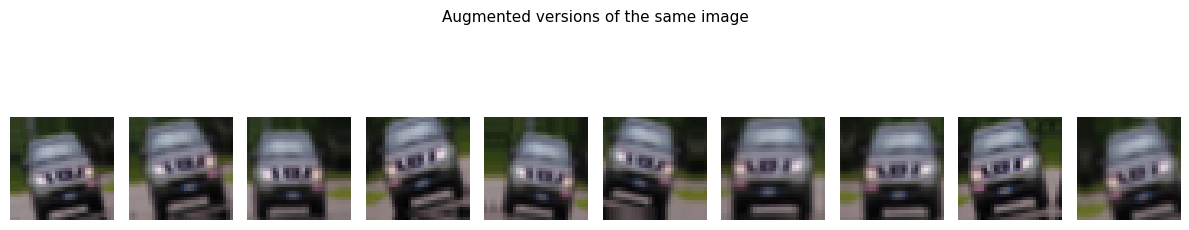

In [5]:
# ── 4. Data augmentation (inside the model → runs on GPU, off at inference)
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(15 / 360),        # ±15 degrees
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.10, 0.10),
], name="data_augmentation")

sample = X_train[:1]
plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(np.clip(data_augmentation(sample, training=True)[0], 0, 1))
    plt.axis("off")
plt.suptitle("Augmented versions of the same image", fontsize=11)
plt.tight_layout(); plt.show()

In [6]:
# ── 5. Build the CNN ────────────────────────────────────────────────
def conv_block(x, filters, dropout):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    return layers.Dropout(dropout)(x)

def build_cnn(input_shape=(32, 32, 3), num_classes=10):
    inputs = keras.Input(shape=input_shape, name="input")
    x = data_augmentation(inputs)
    x = conv_block(x, 32, 0.25)
    x = conv_block(x, 64, 0.30)
    x = conv_block(x, 128, 0.40)
    x = layers.Flatten()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.50)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="output")(x)
    return keras.Model(inputs, outputs, name="CIFAR10_CNN")

model = build_cnn()
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

try:
    keras.utils.plot_model(model, show_shapes=True, show_layer_names=True,
                           to_file="model_architecture.png", dpi=80)
except Exception as e:
    print("plot_model skipped:", e)

Model: "CIFAR10_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,08

 Total params: 1,345,066 (5.13 MB)

 Trainable params: 1,343,146 (5.12 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [7]:
# ── 6. Input pipelines ──────────────────────────────────────────────
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train_ohe))
            .shuffle(len(X_train), seed=SEED)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE))

val_ds = (tf.data.Dataset.from_tensor_slices((X_val, y_val_ohe))
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE))

In [8]:
# ── 7. Callbacks (all watch val_loss → saved model == restored model)
callbacks = [
    EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    ModelCheckpoint("best_cnn_model.keras", monitor="val_loss", save_best_only=True, verbose=1),
]

In [9]:
# ── 8. Train ────────────────────────────────────────────────────────
EPOCHS = 100        # EarlyStopping stops when val_loss stops improving
history = model.fit(train_ds, epochs=EPOCHS, validation_data=val_ds,
                    callbacks=callbacks, verbose=1)
print("\nTraining complete.")

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.3102 - loss: 2.2424
Epoch 1: val_loss improved from None to 1.42898, saving model to best_cnn_model.keras

Epoch 1: finished saving model to best_cnn_model.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 24ms/step - accuracy: 0.3753 - loss: 1.8740 - val_accuracy: 0.4958 - val_loss: 1.4290 - learning_rate: 0.0010
Epoch 2/100
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4847 - loss: 1.4271
Epoch 2: val_loss did not improve from 1.42898
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - accuracy: 0.5129 - loss: 1.3599 - val_accuracy: 0.4944 - val_loss: 1.6573 - learning_rate: 0.0010
Epoch 3/100
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5728 - loss: 1.1949
Epoch 3: val_loss improved from 1.42898 to 1.18184, saving model to best_cnn_model.keras

Epoch 3: finished saving model to best_cnn_model.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - accuracy: 0.5870 - loss: 1.1602 - val_accuracy: 0.5960 - val_loss: 1.18

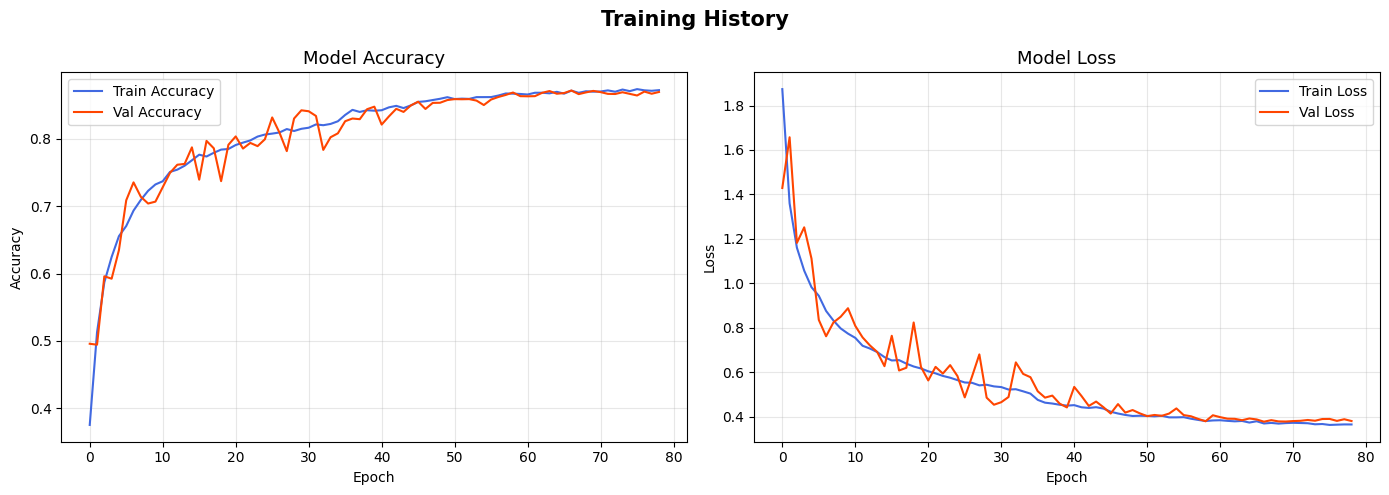

In [10]:
# ── 9. Accuracy & loss curves ───────────────────────────────────────
def plot_history(history):
    h = history.history
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    for ax, key, title in [(ax1, "accuracy", "Accuracy"), (ax2, "loss", "Loss")]:
        ax.plot(h[key], label=f"Train {title}", color="royalblue")
        ax.plot(h[f"val_{key}"], label=f"Val {title}", color="orangered")
        ax.set_title(f"Model {title}", fontsize=13)
        ax.set_xlabel("Epoch"); ax.set_ylabel(title)
        ax.legend(); ax.grid(alpha=0.3)
    plt.suptitle("Training History", fontsize=15, fontweight="bold")
    plt.tight_layout(); plt.show()

plot_history(history)

In [11]:
# ── 10. Evaluate on the test set ────────────────────────────────────
test_loss, test_acc = model.evaluate(X_test, y_test_ohe, verbose=0)
print(f"Test Accuracy : {test_acc * 100:.2f} %")
print(f"Test Loss     : {test_loss:.4f}")

Test Accuracy : 86.14 %
Test Loss     : 0.4190


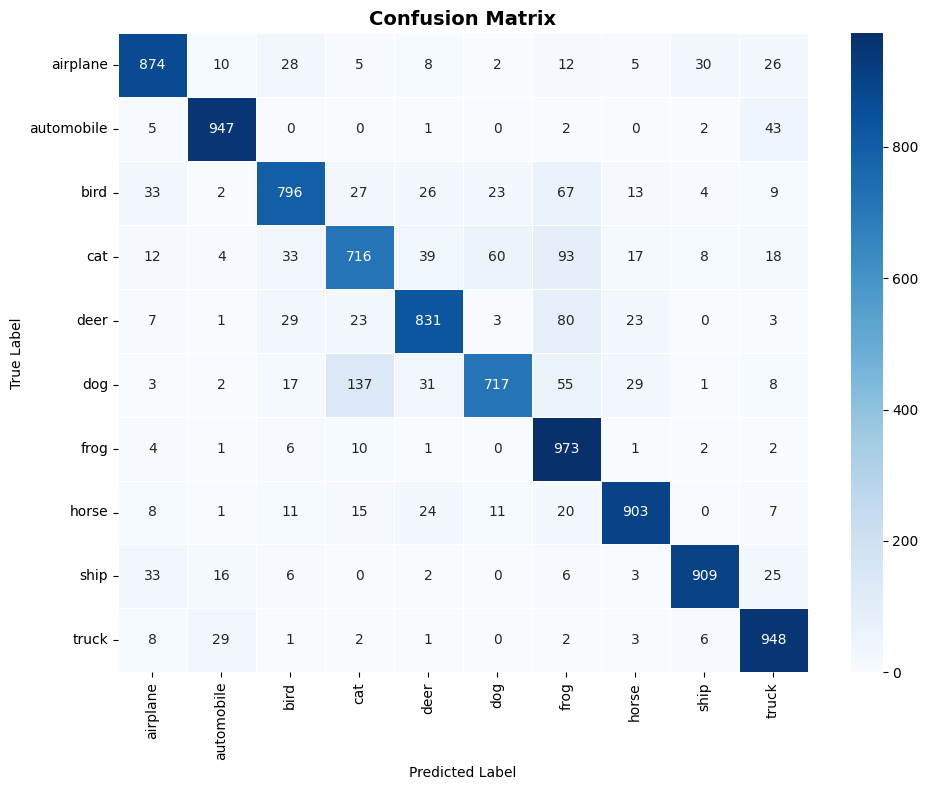

              precision    recall  f1-score   support

    airplane     0.8855    0.8740    0.8797      1000
  automobile     0.9348    0.9470    0.9409      1000
        bird     0.8587    0.7960    0.8262      1000
         cat     0.7658    0.7160    0.7401      1000
        deer     0.8620    0.8310    0.8462      1000
         dog     0.8787    0.7170    0.7896      1000
        frog     0.7427    0.9730    0.8424      1000
       horse     0.9057    0.9030    0.9044      1000
        ship     0.9449    0.9090    0.9266      1000
       truck     0.8705    0.9480    0.9076      1000

    accuracy                         0.8614     10000
   macro avg     0.8649    0.8614    0.8604     10000
weighted avg     0.8649    0.8614    0.8604     10000



In [12]:
# ── 11. Confusion matrix & classification report ────────────────────
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5)
plt.title("Confusion Matrix", fontsize=14, fontweight="bold")
plt.ylabel("True Label"); plt.xlabel("Predicted Label")
plt.tight_layout(); plt.show()

print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

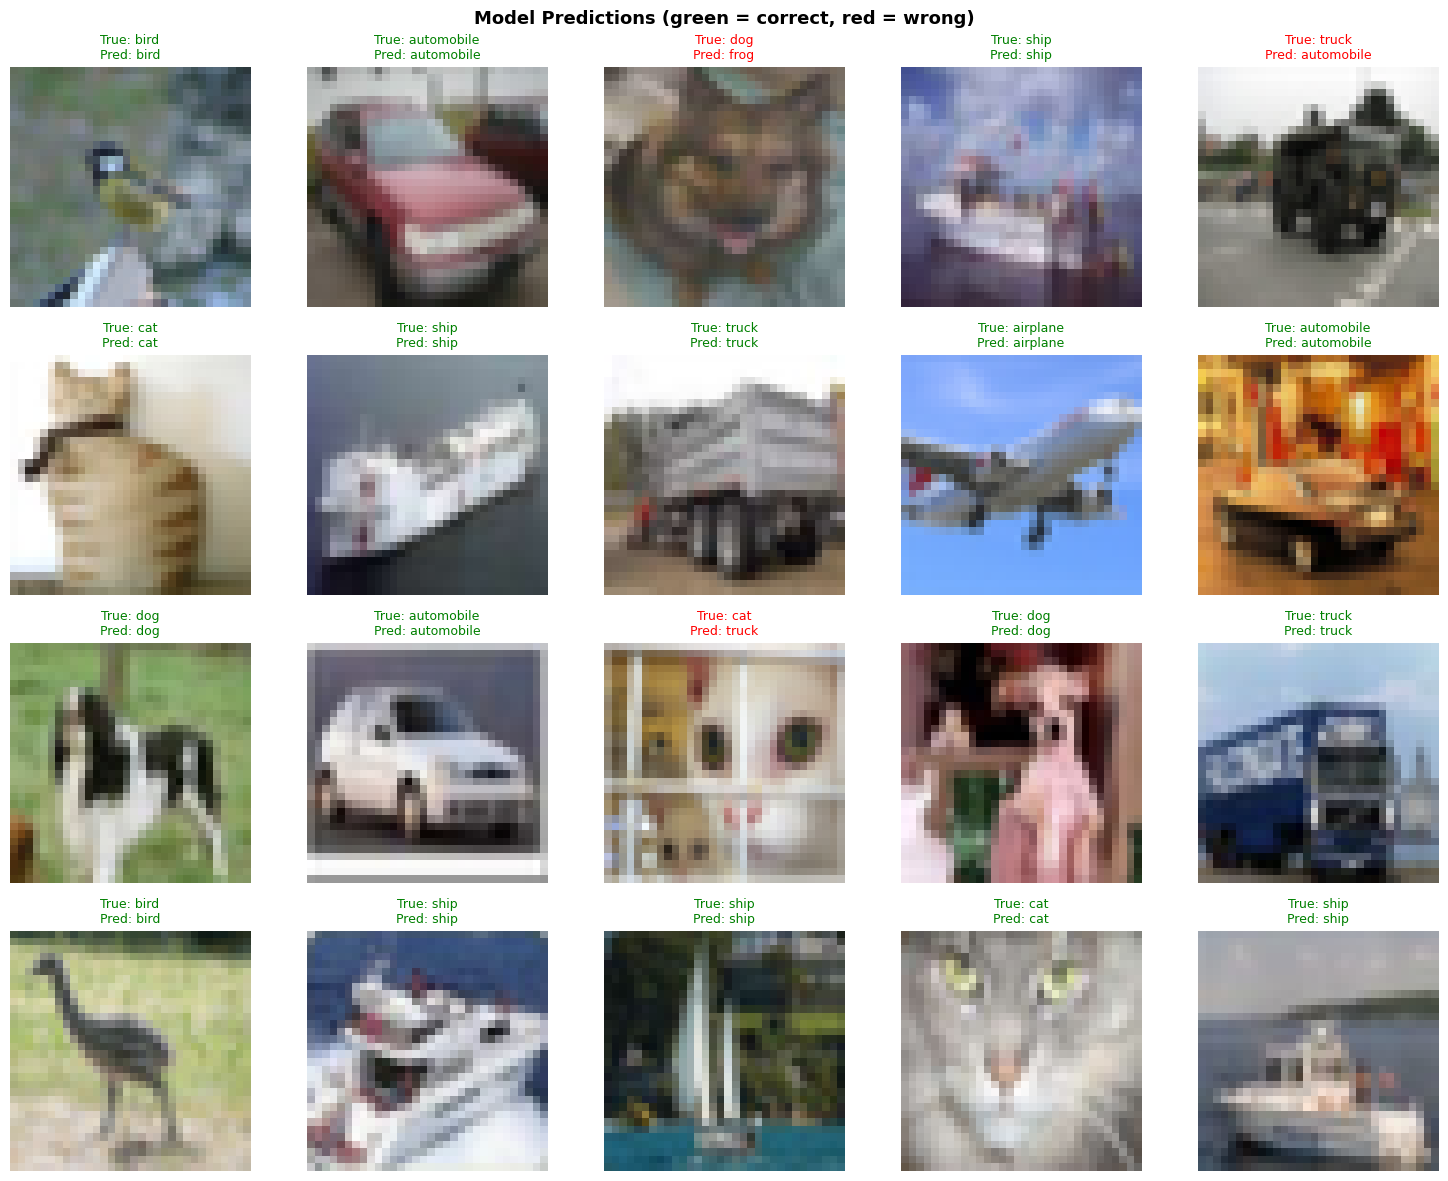

In [13]:
# ── 12. Visualise random predictions ────────────────────────────────
def show_predictions(n=20, cols=5):
    idx = np.random.choice(len(X_test), n, replace=False)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, idx):
        ok = y_test[i] == y_pred[i]
        ax.imshow(X_test[i])
        ax.set_title(f"True: {CLASS_NAMES[y_test[i]]}\nPred: {CLASS_NAMES[y_pred[i]]}",
                     fontsize=9, color="green" if ok else "red")
    plt.suptitle("Model Predictions (green = correct, red = wrong)",
                 fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()

show_predictions(20)

In [14]:
# ── 13. Save & reload the model ─────────────────────────────────────
model.save("cnn_cifar10_final.keras")
loaded_model = keras.models.load_model("cnn_cifar10_final.keras")
_, reloaded_acc = loaded_model.evaluate(X_test, y_test_ohe, verbose=0)
print(f"Saved → cnn_cifar10_final.keras   (reloaded accuracy: {reloaded_acc * 100:.2f} %)")

# Optional: download the model to your computer
# from google.colab import files; files.download("cnn_cifar10_final.keras")

Saved → cnn_cifar10_final.keras   (reloaded accuracy: 86.14 %)


True class      : deer
Predicted class : deer  (91.6 %)

  airplane       0.1%  
  automobile     0.0%  
  bird           0.1%  
  cat            3.2%  █
  deer          91.6%  ███████████████████████████
  dog            4.6%  █
  frog           0.2%  
  horse          0.1%  
  ship           0.0%  
  truck          0.0%  


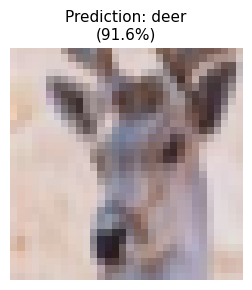

In [15]:
# ── 14. Single-image prediction ─────────────────────────────────────
def predict_single(image_array, model=loaded_model):
    """image_array: (32, 32, 3) array, pixel values 0-255 or 0-1."""
    img = np.asarray(image_array, dtype="float32")
    if img.max() > 1.0:
        img = img / 255.0
    probs = model.predict(img[np.newaxis], verbose=0)[0]
    top = int(np.argmax(probs))

    print(f"Predicted class : {CLASS_NAMES[top]}  ({probs[top] * 100:.1f} %)\n")
    for name, p in zip(CLASS_NAMES, probs):
        print(f"  {name:12s} {p * 100:5.1f}%  {'█' * round(p * 30)}")

    plt.figure(figsize=(3, 3))
    plt.imshow(img)                      # always the normalised 0-1 image
    plt.title(f"Prediction: {CLASS_NAMES[top]}\n({probs[top] * 100:.1f}%)", fontsize=11)
    plt.axis("off"); plt.tight_layout(); plt.show()

i = np.random.randint(len(X_test))
print("True class      :", CLASS_NAMES[y_test[i]])
predict_single(X_test[i])

In [16]:
# ── 15. Gradio app: labels, prediction function, example images ─────
import gradio as gr

# Separate list for the web app - CLASS_NAMES stays plain for matplotlib
DISPLAY_NAMES = ['airplane ✈️', 'automobile 🚗', 'bird 🐦', 'cat 🐱', 'deer 🦌',
                 'dog 🐶', 'frog 🐸', 'horse 🐴', 'ship 🚢', 'truck 🚛']

app_model = keras.models.load_model("cnn_cifar10_final.keras")

def predict(image):
    """Gradio numpy image → dict of class probabilities."""
    if image is None:                               # Submit clicked with no image
        return {}
    img = Image.fromarray(image).convert("RGB")     # handles RGBA / grayscale
    w, h = img.size
    s = min(w, h)                                   # centre-crop to a square
    img = img.crop(((w - s) // 2, (h - s) // 2, (w + s) // 2, (h + s) // 2))
    img = img.resize((32, 32), Image.LANCZOS)
    arr = np.asarray(img, dtype="float32")[np.newaxis] / 255.0
    probs = app_model.predict(arr, verbose=0)[0]
    return {DISPLAY_NAMES[i]: float(probs[i]) for i in range(NUM_CLASSES)}

# Save one test image per class (upscaled) to use as clickable examples
example_paths = []
for c in range(NUM_CLASSES):
    idx = int(np.where(y_test == c)[0][0])
    path = f"example_{CLASS_NAMES[c]}.png"
    Image.fromarray((X_test[idx] * 255).astype("uint8")).resize((128, 128), Image.NEAREST).save(path)
    example_paths.append([path])
print("Example images saved:", len(example_paths))

Example images saved: 10


In [17]:
# ── 16. Build & launch the Gradio interface ─────────────────────────
demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(
        type="numpy",
        label="Upload an image (airplane, car, bird, cat, deer, dog, frog, horse, ship, truck)",
    ),
    outputs=gr.Label(num_top_classes=3, label="Top Predictions"),
    title="🖼️ CNN Image Classifier — CIFAR-10",
    description=(
        "Upload any image and the CNN will classify it into one of 10 categories.\n\n"
        "**Classes:** Airplane · Automobile · Bird · Cat · Deer · Dog · Frog · Horse · Ship · Truck\n\n"
        "Tip: photos where the object fills most of the frame work best."
    ),
    examples=example_paths,
    flagging_mode="never",
)

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://58403dcede43882f2d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
